# Harbor -- Exploratory Data Analysis

This notebook explores the raw synthetic data *before* any modeling
assumptions are baked into `pipelines/`. Business logic (feature
engineering, model training) lives in `src/harbor/`, not here -- this
notebook is for looking at the data and explaining what we see, which is
what motivated several modeling decisions downstream (e.g. why time-aware
snapshots are needed, why static attributes are weak churn predictors).

Run `python pipelines/run_data_generation.py` (and, for the later sections,
`run_training_pipeline.py` + `run_segmentation.py`) before running this
notebook.

In [1]:
import sys
from pathlib import Path

# `harbor` is pip-installed in editable mode (`pip install -e .`), so this
# works regardless of which directory the notebook is launched from; the
# sys.path fallback only matters if it hasn't been installed yet.
try:
    import harbor  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from harbor.config import load_config

cfg = load_config()
raw_dir = cfg.path(key="raw_dir")
processed_dir = cfg.path(key="processed_dir")
data_cfg = cfg.section("data")

accounts = pd.read_csv(raw_dir / data_cfg["accounts_file"])
usage = pd.read_csv(raw_dir / data_cfg["usage_file"])
tickets = pd.read_csv(raw_dir / data_cfg["tickets_file"])
experiment = pd.read_csv(raw_dir / data_cfg["experiment_file"])

print(f"accounts: {len(accounts):,} rows")
print(f"monthly_usage: {len(usage):,} rows ({usage['month_index'].nunique()} months)")
print(f"support_tickets: {len(tickets):,} rows")
print(f"experiment_assignments: {len(experiment):,} rows")

accounts: 3,000 rows
monthly_usage: 90,000 rows (30 months)
support_tickets: 13,798 rows
experiment_assignments: 808 rows


## 1. Portfolio composition

Plan tier, industry, and size-band mix -- this is the "static attribute"
information available at signup, before any behavioral data exists.

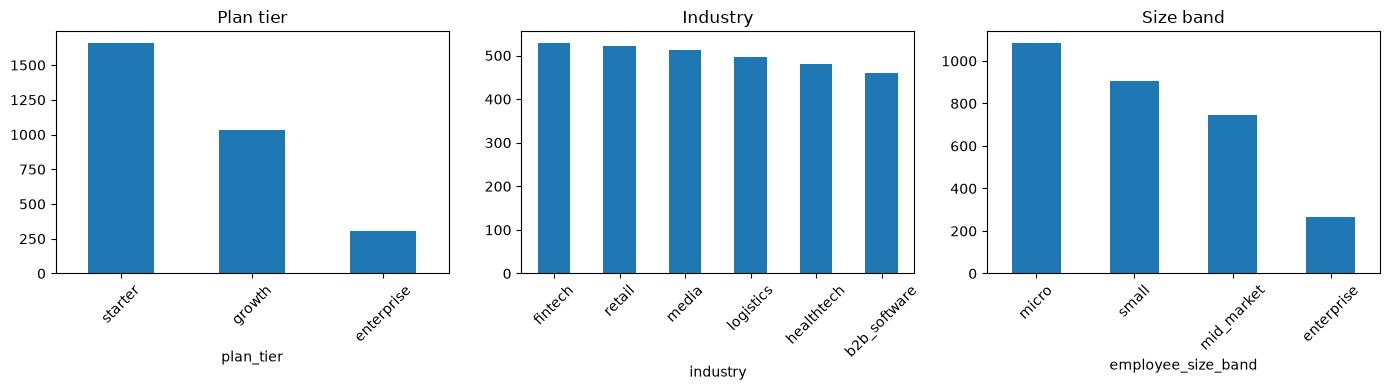

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
accounts["plan_tier"].value_counts().plot(kind="bar", ax=axes[0], title="Plan tier")
accounts["industry"].value_counts().plot(kind="bar", ax=axes[1], title="Industry")
accounts["employee_size_band"].value_counts().plot(kind="bar", ax=axes[2], title="Size band")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Takeaway**: the portfolio is starter-plan-heavy (~55%), which is
exactly why plan mix alone is a weak churn signal -- most accounts share the
same plan regardless of whether they're healthy or at risk. This is one
reason the baseline churn model (static attributes only) barely beats
random in `docs/EVALUATION_REPORT.md`.

## 2. Churn accumulates steadily, not in one big wave

Plotting the fraction of accounts still active by month shows whether churn
is a smooth, ongoing hazard (what the model needs to predict continuously)
or a one-time cliff (which would need a totally different approach).

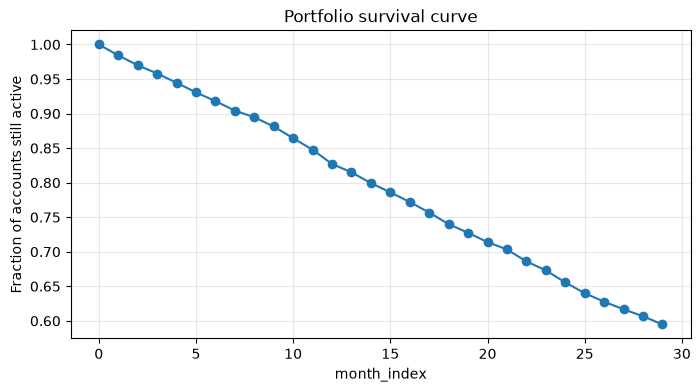

Active at month 0: 100.0%
Active at last month: 59.5%


In [3]:
active_by_month = usage.groupby("month_index")["is_active"].mean()
plt.figure(figsize=(8, 4))
active_by_month.plot(marker="o")
plt.ylabel("Fraction of accounts still active")
plt.xlabel("month_index")
plt.title("Portfolio survival curve")
plt.grid(alpha=0.3)
plt.show()

print(f"Active at month 0: {active_by_month.iloc[0]:.1%}")
print(f"Active at last month: {active_by_month.iloc[-1]:.1%}")

## 3. Usage decline precedes churn

Comparing average trailing engagement for accounts that eventually churn
vs. accounts that survive the full window -- if churners look identical to
survivors until the month they leave, behavioral features would be
useless. If they diverge earlier, that's exactly what the trailing-window
features in `build_features.py` are designed to capture.

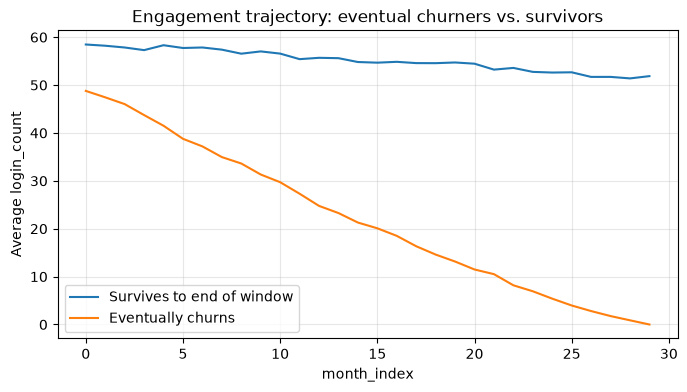

In [4]:
last_active_month = usage[usage["is_active"]].groupby("account_id")["month_index"].max()
eventually_churns = (last_active_month < usage["month_index"].max()).reindex(accounts["account_id"]).fillna(False)

usage_labeled = usage.merge(
    eventually_churns.rename("eventually_churns").reset_index().rename(columns={"index": "account_id"}),
    on="account_id", how="left",
)

login_by_group = usage_labeled.groupby(["month_index", "eventually_churns"])["login_count"].mean().unstack()
plt.figure(figsize=(8, 4))
login_by_group.plot(ax=plt.gca())
plt.ylabel("Average login_count")
plt.xlabel("month_index")
plt.title("Engagement trajectory: eventual churners vs. survivors")
plt.legend(["Survives to end of window", "Eventually churns"])
plt.grid(alpha=0.3)
plt.show()

**Takeaway**: eventual churners show visibly lower and declining
engagement well before they leave, not just in their final month -- this is
the signal `login_trend_3v6` and the trailing-average features are built to
capture, and why the classical/advanced churn models (which use these
features) so clearly outperform the static-attribute baseline.

## 4. Support ticket patterns

Category mix and sentiment distribution -- this is the raw material the
NLP classifier in `harbor.nlp.ticket_analysis` learns from.

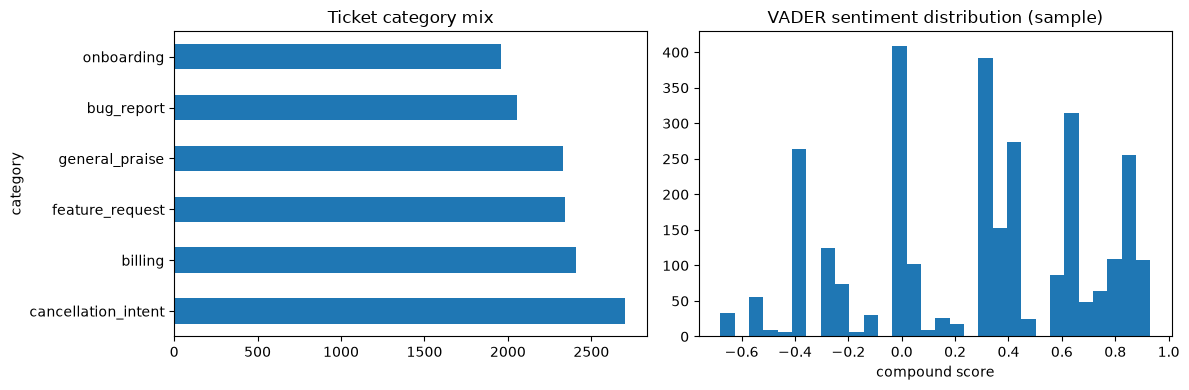

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tickets["category"].value_counts().plot(kind="barh", ax=axes[0], title="Ticket category mix")

from harbor.nlp.ticket_analysis import vader_compound_scores

sample = tickets["text"].sample(min(3000, len(tickets)), random_state=42)
scores = vader_compound_scores(sample)
axes[1].hist(scores, bins=30)
axes[1].set_title("VADER sentiment distribution (sample)")
axes[1].set_xlabel("compound score")
plt.tight_layout()
plt.show()

**Takeaway**: sentiment is bimodal-ish rather than uniformly neutral --
consistent with the injected structure (negative sentiment concentrated in
billing/bug/cancellation-intent tickets, positive in praise/feature
requests) but with enough overlap that a lexicon baseline (VADER) is
noticeably worse than a trained classifier, as shown in
`docs/EVALUATION_REPORT.md` section 1.

## 5. MRR trend by plan tier

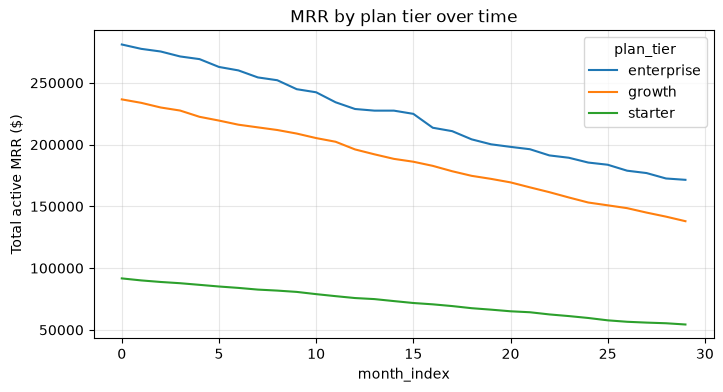

In [6]:
mrr_by_month_plan = usage[usage["is_active"]].merge(
    accounts[["account_id", "plan_tier"]], on="account_id"
).groupby(["month_index", "plan_tier"])["mrr"].sum().unstack()

plt.figure(figsize=(8, 4))
mrr_by_month_plan.plot(ax=plt.gca())
plt.ylabel("Total active MRR ($)")
plt.xlabel("month_index")
plt.title("MRR by plan tier over time")
plt.grid(alpha=0.3)
plt.show()

**Takeaway**: MRR trend dominates over any seasonal pattern in this
simulation -- which is exactly why `seasonal_naive` underperforms plain
`naive` in the forecasting backtest (section 3 of the evaluation report):
lagging by 12 months captures a much lower value than 1 month ago, because
the portfolio is still net-growing/shrinking, not cycling seasonally.

## 6. Behavioral segments (if segmentation has been run)

Reads `data/processed/segmentation_projection.csv`, produced by
`pipelines/run_segmentation.py`. Skips gracefully if that pipeline hasn't
been run yet.

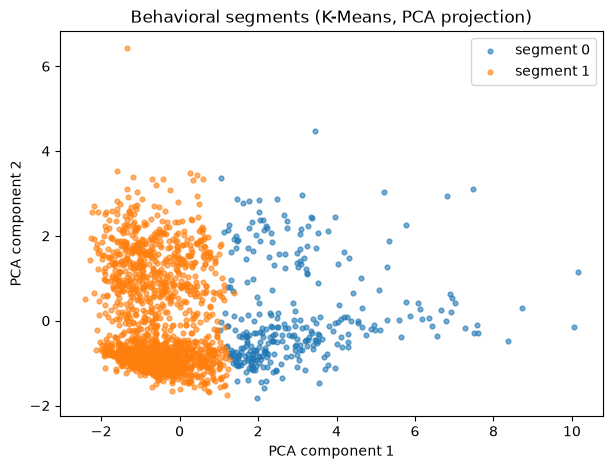

              current_mrr  churn_within_horizon
kmeans_label                                   
0              624.042154              0.019293
1              120.809771              0.066158


In [7]:
seg_path = processed_dir / "segmentation_projection.csv"
if seg_path.exists():
    projection = pd.read_csv(seg_path)
    plt.figure(figsize=(7, 5))
    for label, group in projection.groupby("kmeans_label"):
        plt.scatter(group["pca_x"], group["pca_y"], s=12, alpha=0.6, label=f"segment {label}")
    plt.xlabel("PCA component 1")
    plt.ylabel("PCA component 2")
    plt.title("Behavioral segments (K-Means, PCA projection)")
    plt.legend()
    plt.show()

    print(projection.groupby("kmeans_label")[["current_mrr", "churn_within_horizon"]].mean())
else:
    print("Run `python pipelines/run_segmentation.py` first to populate this section.")

## Summary

- Static account attributes (plan/industry/size) carry almost no churn
  signal on their own -- the portfolio is too plan-homogeneous for that to
  work, which is why the baseline churn model is barely better than random.
- Engagement decline is visible *before* churn, not just at the moment of
  churn -- this justifies the trailing-window behavioral features that
  drive most of the classical/advanced models' lift.
- Ticket sentiment has real but noisy structure -- enough for a trained
  classifier to clearly beat a lexicon baseline, not enough for either to
  be perfect (nor should it be, on real-world-flavored text).
- MRR trend dominates seasonality in this portfolio, which is the direct
  explanation for why `seasonal_naive` is the *worst* forecasting method
  in the backtest, not an oversight.
- Behavioral clustering finds a real (if modest-separation) split between a
  smaller high-value/low-churn segment and a larger mass-market/higher-churn
  segment -- see `docs/EVALUATION_REPORT.md` section 6 for the full
  method comparison and why we don't over-claim "clusters" that don't
  replicate.